# CFAR Comparison — CA vs OS vs GO

Classical CFAR detection on the Range-Doppler maps: mechanism, **threshold calibration**,
**window-geometry tuning**, and a fair comparison. All scoring goes through the shared
`src/eval` module, so these same rules later score the deep-learning detector.

Sections:
1. Setup
2. One frame — RD map, CFAR threshold, detections (the visual)
3. Noise estimate — why one threshold formula is not enough
4. **Threshold calibration** (Monte-Carlo) — putting all three at the same Pfa
5. **Window-geometry tuning** (guard / training cells)
6. **ROC** — the fair comparison (Pd at matched Pfa)
7. Pd vs cell SNR
8. Runtime vs robustness
9. Per-scenario summary

> Key idea: you cannot rank detectors at a single Pfa unless they are actually AT that Pfa.
> Sections 4 and 6 are what make the comparison honest.

In [1]:
import sys, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from radar.config import RadarConfig
from cfar import CfarConfig, cfar_ratio_map, extract_detections, all_peaks
from cfar.calibrate import calibrate_all, make_noise_power_frames
from eval import MatchConfig, evaluate_frame, aggregate, roc_curve, pd_vs_snr

DATA = ROOT / "data"
RC = RadarConfig()
MC = MatchConfig(tol_r=1, tol_v=1)
KINDS = ["CA", "OS", "GO"]
COLORS = {"CA": "tab:blue", "OS": "tab:green", "GO": "tab:orange"}
# Distinct line styles so overlapping curves stay individually visible (the methods
# coincide on clean data, which would otherwise hide whichever is drawn first).
STYLE = {"CA": dict(ls="-",  marker="o", lw=2.6, ms=7, alpha=0.9),
         "OS": dict(ls="--", marker="s", lw=1.8, ms=5, alpha=0.9),
         "GO": dict(ls=":",  marker="^", lw=1.8, ms=5, alpha=0.9)}
GUARD, TRAIN = 2, 8   # window geometry (justified in section 5)

def load_frame(fd):
    power = np.load(fd / "rd_map_mag.npy") ** 2
    lab = pd.read_csv(fd / "labels.csv")
    tru = lab[["range_bin", "velocity_bin"]].to_numpy()
    snr = lab["cell_snr_db"].to_numpy() if "cell_snr_db" in lab else np.full(len(tru), np.nan)
    return power, tru, snr

def frames_of(ds):
    return sorted((DATA / ds / "frames").iterdir())

print("root:", ROOT)
print("scenarios:", [p.name for p in sorted(DATA.iterdir()) if p.is_dir()])

root: C:\Users\USER\Desktop\Radar-fyp\My work\Simulations
scenarios: ['clean_debug', 'close_targets_debug', 'clutter_debug', 'multi_target_debug', 'multipath_debug', 'noise_only_debug', 'snr_sweep_debug']


## 2. One frame — RD map, CFAR threshold, and detections

The three panels: the RD power, the CA-CFAR threshold surface (adapts to the local level), and the detections (green) vs true targets (cyan).

C:\Users\USER\AppData\Local\Temp\ipykernel_22204\1347933596.py:11: RuntimeWarning: divide by zero encountered in divide
  noise = np.where(ratio>0, power/ratio, np.nan)


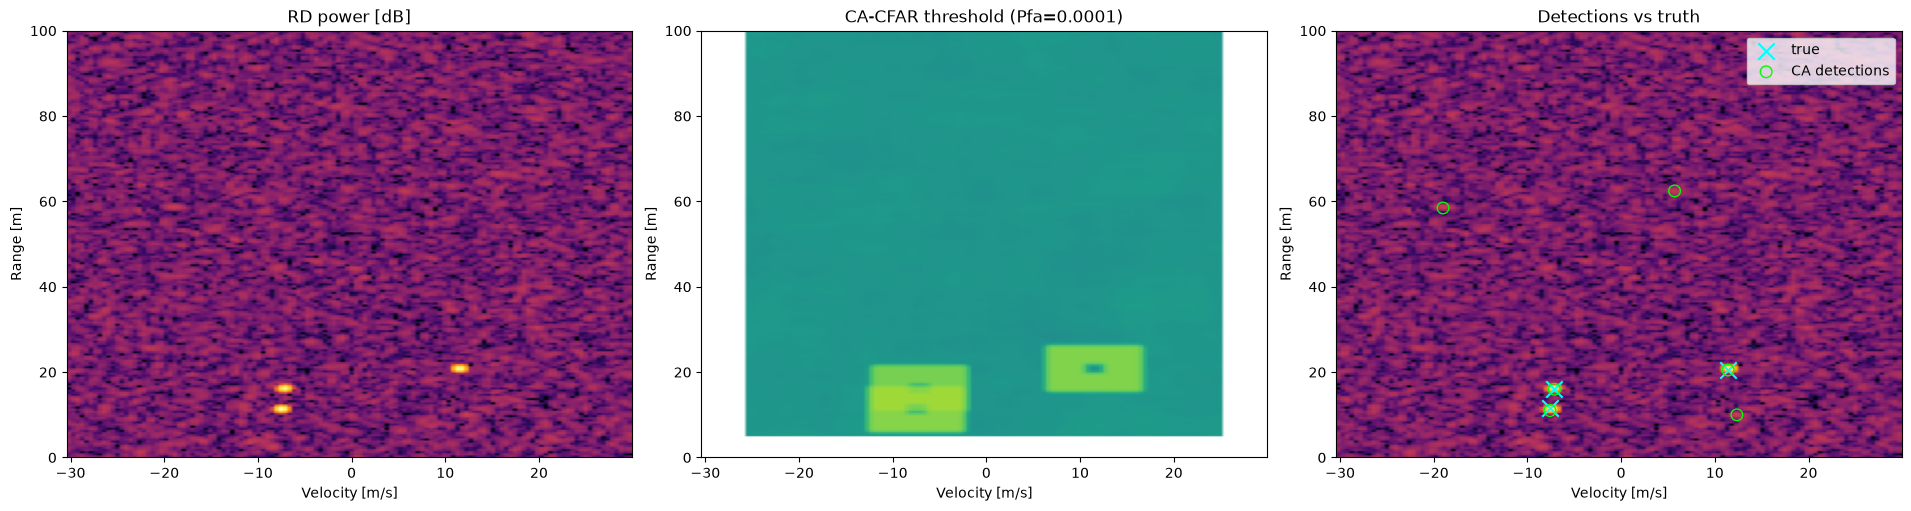

7 detections, alpha=9.31


In [2]:
fd = DATA / "clean_debug" / "frames" / "frame_000000"
power, tru, _ = load_frame(fd)
r_ax = np.load(fd / "range_axis.npy"); v_ax = np.load(fd / "velocity_axis.npy")
extent = [v_ax[0], v_ax[-1], r_ax[0], r_ax[-1]]

cfg = CfarConfig(kind="CA", guard=GUARD, train=TRAIN, pfa=1e-4)
ratio, valid, alpha = cfar_ratio_map(power, cfg)
det = extract_detections(ratio, valid, alpha, nms_size=5)

power_db = 10*np.log10(power/power.max() + 1e-12)
noise = np.where(ratio>0, power/ratio, np.nan)
thr_db = 10*np.log10(alpha*noise/power.max() + 1e-12)

fig, ax = plt.subplots(1, 3, figsize=(19, 5), constrained_layout=True)
for a in ax:
    a.set_xlabel("Velocity [m/s]"); a.set_ylabel("Range [m]"); a.set_ylim(0, 100)
ax[0].imshow(power_db, aspect="auto", origin="lower", extent=extent, cmap="inferno", vmin=-60, vmax=0)
ax[0].set_title("RD power [dB]")
ax[1].imshow(thr_db, aspect="auto", origin="lower", extent=extent, cmap="viridis", vmin=-60, vmax=0)
ax[1].set_title(f"CA-CFAR threshold (Pfa={cfg.pfa:g})")
ax[2].imshow(power_db, aspect="auto", origin="lower", extent=extent, cmap="inferno", vmin=-60, vmax=0)
ax[2].scatter(v_ax[tru[:,1]], r_ax[tru[:,0]], marker="x", s=140, color="cyan", label="true")
if len(det):
    ax[2].scatter(v_ax[det[:,1].astype(int)], r_ax[det[:,0].astype(int)], s=70,
                  facecolors="none", edgecolors="lime", label="CA detections")
ax[2].legend(loc="upper right"); ax[2].set_title("Detections vs truth")
plt.show()
print(f"{len(det)} detections, alpha={alpha:.2f}")

## 3. Noise estimate — why one threshold formula is not enough

On homogeneous noise every method's noise estimate should track the true noise power. But
each uses a **different statistic**, so they sit at different levels:

| method | statistic | estimate / true |
|---|---|---|
| CA | arithmetic mean of the training cells | ≈ 1.00× |
| OS | 75th-percentile (k-th ordered) cell | ≈ 1.39× (= ln 4, the 0.75 quantile of exponential noise) |
| GO | max of the two half-window means | ≈ 1.09× |

The CA threshold multiplier `alpha = N(Pfa^(-1/N) - 1)` is derived **for the arithmetic mean
only**. Applying it to OS/GO does not give the intended Pfa (with this geometry it left them
far too conservative). Section 4 fixes that.

In [3]:
power_n, _, _ = load_frame(DATA / "noise_only_debug" / "frames" / "frame_000000")
rows = []
for k in KINDS:
    cfg = CfarConfig(kind=k, guard=GUARD, train=TRAIN)
    ratio, valid, _ = cfar_ratio_map(power_n, cfg)
    est = power_n[valid] / np.where(ratio[valid] > 0, ratio[valid], np.nan)
    rows.append({"method": k, "noise_est / true": np.nanmean(est)/power_n[valid].mean()})
pd.DataFrame(rows).set_index("method")

,noise_est / true
method,
CA,1.001570
OS,1.394011
GO,1.091638


## 4. Threshold calibration (Monte-Carlo)

**Problem.** Only CA has a closed-form `alpha(Pfa)`. To put CA, OS and GO at the *same*
false-alarm rate we calibrate each empirically:

1. Process many **pure-noise** CPIs through the identical RD chain → noise power maps.
2. Run the CFAR ratio map (CUT ÷ local noise estimate) on each.
3. Pool the ratio over all validly-tested cells.
4. The threshold for a target Pfa is the **(1 − Pfa) quantile** of that pooled ratio — the
   level exceeded by only a fraction Pfa of noise cells.

This works for *any* CFAR statistic. We validate it by checking the empirical CA threshold
matches the analytic formula. (Implemented in `src/cfar/calibrate.py`.)

*Takes ~1–2 min because the OS rank filter is run over many noise frames.*

In [4]:
# Validate: empirical vs analytic CA threshold (they should agree to a few %).
val = []
for pfa in [1e-3, 1e-4]:
    a_all = calibrate_all(RC, pfa, guard=GUARD, train=TRAIN, kinds=("CA",), n_frames=40, seed=1)
    ana = CfarConfig(kind="CA", guard=GUARD, train=TRAIN, pfa=pfa).alpha()
    val.append({"Pfa": pfa, "analytic_CA": round(ana, 3), "empirical_CA": round(a_all["CA"], 3),
                "diff_%": round(100*(a_all["CA"]-ana)/ana, 1)})
pd.DataFrame(val).set_index("Pfa")

,analytic_CA,empirical_CA,diff_%
Pfa,,,
0.0010,6.965,7.156,2.7
0.0001,9.313,9.762,4.8


In [5]:
# Calibrate alpha for CA/OS/GO at the two operating Pfa values we use below. Cache it.
CAL_ALPHA = {pfa: calibrate_all(RC, pfa, guard=GUARD, train=TRAIN, n_frames=40, seed=1)
             for pfa in [1e-4, 1e-3]}
pd.DataFrame(CAL_ALPHA).rename_axis("method").rename(columns=lambda p: f"alpha @ Pfa={p:g}")

,alpha @ Pfa=0.0001,alpha @ Pfa=0.001
method,,
CA,9.762382,7.155736
OS,6.942640,5.154038
GO,9.084870,6.674253


In [6]:
# Verify the calibrated thresholds on INDEPENDENT noise (different seed): measured Pfa ~ target.
rows = []
for pfa in [1e-4, 1e-3]:
    for k in KINDS:
        cfg = CfarConfig(kind=k, guard=GUARD, train=TRAIN)
        exc = tot = 0
        for power in make_noise_power_frames(RC, 30, seed=999):
            ratio, valid, _ = cfar_ratio_map(power, cfg)
            exc += int((ratio[valid] > CAL_ALPHA[pfa][k]).sum()); tot += int(valid.sum())
        rows.append({"target_Pfa": pfa, "method": k, "measured_Pfa": exc/tot})
pd.DataFrame(rows).pivot(index="method", columns="target_Pfa", values="measured_Pfa")

target_Pfa,0.0001,0.0010
method,,
CA,0.000081,0.000993
GO,0.000086,0.000981
OS,0.000097,0.001020


## 5. Window-geometry tuning (guard / training cells)

- **Guard = 2** covers the target mainlobe (measured: −20 dB at ±2 bins, < −90 dB by ±3), so
  the target's own leakage stays out of the noise estimate.
- **Training cells** trade estimate variance (CFAR loss) against locality. More cells → lower
  loss in homogeneous noise, but a larger window is more likely to straddle a clutter edge.

The sweep below (CA, matched Pfa, on the graded `snr_sweep` set) picks the operating point.
Guard is also varied to confirm it is insensitive.

In [7]:
from cfar.calibrate import calibrate_alpha
def sweep_pd(kind, guard, train, ds="snr_sweep_debug", pfa=1e-3):
    cfg = CfarConfig(kind=kind, guard=guard, train=train)
    a, _ = calibrate_alpha(cfg, RC, pfa, n_frames=40, seed=1)
    evs = []
    for fd in frames_of(ds):
        power, tru, _ = load_frame(fd)
        ratio, valid, _ = cfar_ratio_map(power, cfg)
        det = extract_detections(ratio, valid, a, nms_size=5)
        evs.append(evaluate_frame(det, tru, power.shape, MC))
    return aggregate(evs)["pd"], cfg.num_ref_cells, a

rows = []
for t in [4,6,8,10,12]:
    pd_, n, a = sweep_pd("CA", 2, t)
    rows.append({"train": t, "N_ref": n, "alpha": round(a,2), "Pd(snr_sweep)": round(pd_,3)})
print("Training-size sweep (CA, guard=2, matched Pfa=1e-3):")
display(pd.DataFrame(rows).set_index("train"))
g = []
for gd in [2,3]:
    pd_, n, a = sweep_pd("CA", gd, 8)
    g.append({"guard": gd, "Pd(snr_sweep)": round(pd_,3)})
print("Guard sensitivity (train=8):")
display(pd.DataFrame(g).set_index("guard"))

Training-size sweep (CA, guard=2, matched Pfa=1e-3):


,N_ref,alpha,Pd(snr_sweep)
train,,,
4,144,7.66,0.588
6,264,7.32,0.583
8,416,7.16,0.604
10,600,7.09,0.596
12,816,7.03,0.608


Guard sensitivity (train=8):


,Pd(snr_sweep)
guard,
2,0.604
3,0.596


**Chosen geometry: guard = 2, train = 8.** Pd is nearly flat beyond train ≈ 8 (bigger
windows help only marginally while sacrificing locality for the clutter scenarios), and guard
2 vs 3 is within noise — confirming guard is set by physics, not tuning.

## 6. ROC — the fair comparison

For each method we keep ALL candidate peaks with their ratio score, then sweep the score
threshold. Each setting gives one (Pfa, Pd) point. Because the three ratio statistics live on
different scales, we compare in (Pfa, Pd) space and read off Pd at a matched Pfa — the only
fair way to rank them. (This is independent of section 4's calibration; calibration just marks
where the chosen operating point sits on these curves.)

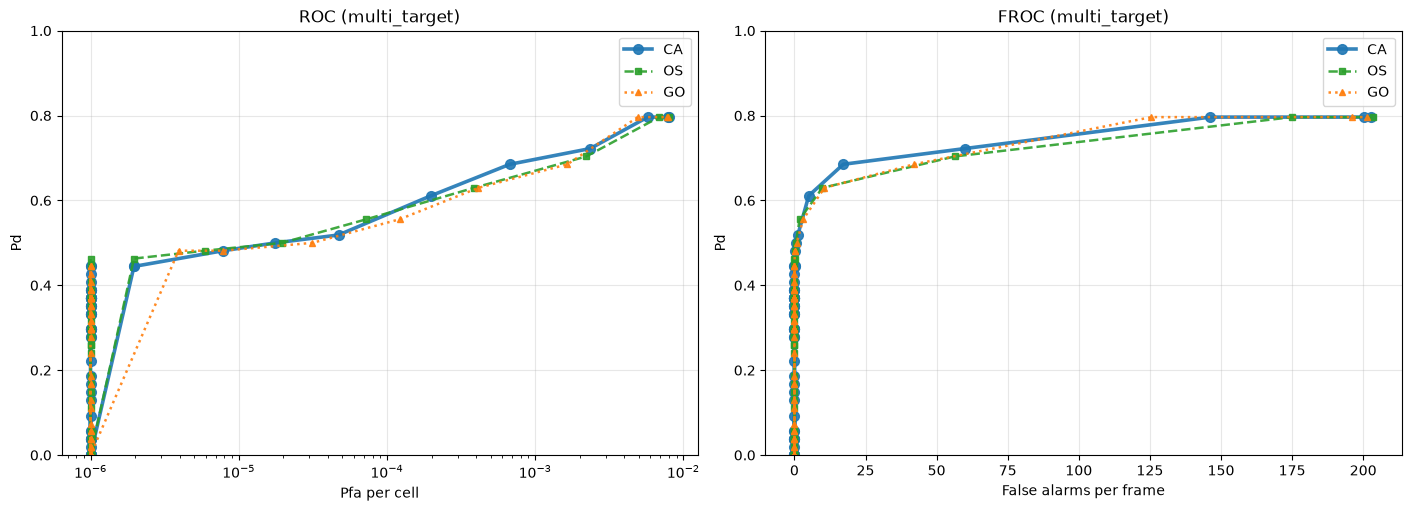

In [8]:
def collect(ds, cfg):
    out = []
    for fd in frames_of(ds):
        power, tru, snr = load_frame(fd)
        ratio, valid, _ = cfar_ratio_map(power, cfg)
        out.append((all_peaks(ratio, valid, nms_size=5), tru, power.shape, valid))
    return out

thr = np.unique(np.concatenate([np.linspace(1, 60, 40), np.logspace(np.log10(60), np.log10(3000), 25)]))
roc = {}
for k in KINDS:
    cfg = CfarConfig(kind=k, guard=GUARD, train=TRAIN)
    roc[k] = roc_curve(collect("multi_target_debug", cfg), thresholds=thr, cfg=MC)

fig, ax = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for k in KINDS:
    d = roc[k].sort_values("pfa_per_cell")
    ax[0].plot(d["pfa_per_cell"].clip(1e-6), d["pd"], color=COLORS[k], label=k, **STYLE[k])
    ax[1].plot(d["fa_per_frame"], d["pd"], color=COLORS[k], label=k, **STYLE[k])
ax[0].set_xscale("log"); ax[0].set_xlabel("Pfa per cell"); ax[0].set_ylabel("Pd"); ax[0].set_title("ROC (multi_target)")
ax[0].legend(); ax[0].grid(alpha=.3); ax[0].set_ylim(0,1)
ax[1].set_xlabel("False alarms per frame"); ax[1].set_ylabel("Pd"); ax[1].set_title("FROC (multi_target)")
ax[1].legend(); ax[1].grid(alpha=.3); ax[1].set_ylim(0,1)
plt.show()

In [9]:
def pd_at_pfa(df, target=1e-3):
    d = df.sort_values("pfa_per_cell")
    return float(np.interp(target, d["pfa_per_cell"], d["pd"]))
pd.DataFrame([{"method": k, "Pd @ Pfa=1e-3": round(pd_at_pfa(roc[k]),3)} for k in KINDS]).set_index("method")

,Pd @ Pfa=1e-3
method,
CA,0.692
OS,0.654
GO,0.656


## 7. Pd vs cell SNR

Detection probability against each target's own measured cell SNR, at the **calibrated**
Pfa=1e-3 operating point (so all three are compared at the same false-alarm rate). The S-curve
is the fundamental detector characteristic.

Distinct line styles (solid CA / dashed OS / dotted GO) keep the three visible: **on this clean,
single-target set they nearly coincide** — CFAR variants only diverge under clutter or
multi-target masking, so here overlapping curves are the expected, correct result. (This plot
belongs on `snr_sweep`, which grades SNR with one clean target; other scenarios do not sweep
SNR and would not be meaningful here.)

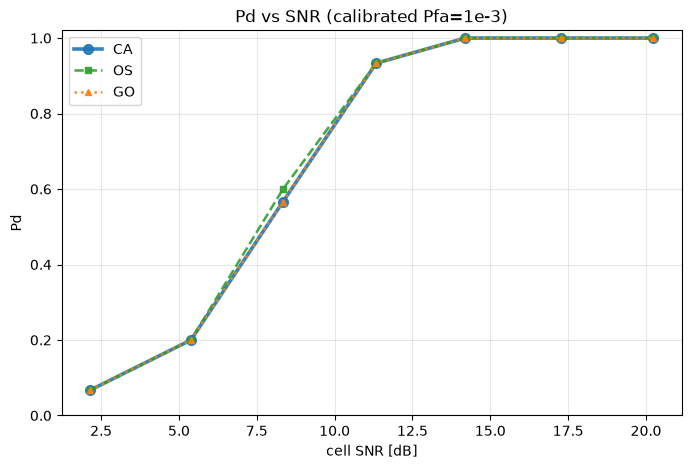

In [10]:
edges = [0,3,6,9,12,15,18,21,24]
fig, ax = plt.subplots(figsize=(8,5))
for k in KINDS:
    cfg = CfarConfig(kind=k, guard=GUARD, train=TRAIN)
    alpha = CAL_ALPHA[1e-3][k]
    frames = []
    for fd in frames_of("snr_sweep_debug"):
        power, tru, snr = load_frame(fd)
        ratio, valid, _ = cfar_ratio_map(power, cfg)
        det = extract_detections(ratio, valid, alpha, nms_size=5)
        frames.append((det, tru, power.shape, snr))
    curve = pd_vs_snr(frames, snr_edges=edges, cfg=MC)
    ax.plot(curve["mean_snr_db"], curve["pd"], color=COLORS[k], label=k, **STYLE[k])
ax.set_xlabel("cell SNR [dB]"); ax.set_ylabel("Pd"); ax.set_title("Pd vs SNR (calibrated Pfa=1e-3)")
ax.grid(alpha=.3); ax.legend(); ax.set_ylim(0,1.02)
plt.show()

## 8. Runtime vs robustness

Mean processing time per frame. OS's robustness (rank filter) costs an order of magnitude more than CA/GO — a real trade-off for the runtime metric.

In [11]:
rows = []
for k in KINDS:
    cfg = CfarConfig(kind=k, guard=GUARD, train=TRAIN)
    t0 = time.perf_counter(); n = 0
    for fd in frames_of("clutter_debug"):
        power, tru, _ = load_frame(fd)
        ratio, valid, _ = cfar_ratio_map(power, cfg)
        _ = extract_detections(ratio, valid, CAL_ALPHA[1e-4][k], nms_size=5); n += 1
    rows.append({"method": k, "ms/frame": round((time.perf_counter()-t0)/n*1000, 1)})
pd.DataFrame(rows).set_index("method")

,ms/frame
method,
CA,5.6
OS,260.8
GO,35.5


## 9. Per-scenario summary

Pd and false-alarms/frame at the **calibrated** Pfa=1e-4 operating point (so all three sit at the same measured false-alarm rate). Read alongside the ROC.

In [12]:
rows = []
for ds in ["clean_debug","clutter_debug","multi_target_debug","close_targets_debug","multipath_debug"]:
    row = {"scenario": ds}
    for k in KINDS:
        cfg = CfarConfig(kind=k, guard=GUARD, train=TRAIN)
        alpha = CAL_ALPHA[1e-4][k]
        evs = []
        for fd in frames_of(ds):
            power, tru, _ = load_frame(fd)
            ratio, valid, _ = cfar_ratio_map(power, cfg)
            det = extract_detections(ratio, valid, alpha, nms_size=5)
            evs.append(evaluate_frame(det, tru, power.shape, MC, valid_mask=valid))
        a = aggregate(evs)
        row[f"{k}_Pd"] = round(a["pd"], 2); row[f"{k}_FA"] = round(a["fa_per_frame"], 1)
    rows.append(row)
pd.DataFrame(rows).set_index("scenario")

,CA_Pd,CA_FA,OS_Pd,OS_FA,GO_Pd,GO_FA
scenario,,,,,,
clean_debug,1.00,2.3,1.00,2.5,1.00,2.4
clutter_debug,1.00,1.8,1.00,2.0,1.00,1.6
multi_target_debug,0.54,1.9,0.56,2.5,0.56,1.9
close_targets_debug,0.50,1.9,0.50,2.1,0.50,1.9
multipath_debug,1.00,1.4,1.00,1.4,1.00,1.6


## Notes for the report

- **Calibration (section 4):** only CA has a closed-form `alpha(Pfa)`; OS and GO were calibrated
  by Monte-Carlo to the same design Pfa (validated against the analytic CA value, agreement a
  few %). This is what lets the single-operating-point tables (7, 9) compare methods fairly.
- **Fair comparison = ROC (section 6)**, read at a matched Pfa. At matched Pfa the classical
  methods are close; CA is optimal in homogeneous noise, OS is robust to interfering targets
  (at a runtime cost), GO controls clutter-edge false alarms (Doppler-axis split).
- **Geometry (section 5):** guard = 2 from the measured mainlobe (insensitive); train = 8 at the
  knee of the CFAR-loss/locality trade-off.
- `close_targets` Pd caps at ~0.5 for every method — a resolution limit (weak partner inside
  the mainlobe), not a detector failure.
- These are DEBUG numbers; final figures come from the frozen datasets. Focus on the shapes.